# AZIMUTH · Cuaderno único 2/2 — Validación por Experimentos Numéricos (VEN)
**Réplica del DOE unifactorial E0–E4 documentado en el Capítulo IV y Anexo III.**

**Muestra:** cinco escenarios × 20 órdenes × 180 s a 1 Hz = **18.000 registros temporales**; unidad experimental estadística: **OT**, no lecturas. **Semilla:** `SEED=2026`. **Ventana del generador VEN:** 19,5–21,5 V, 120–160 A, 12–14 L/min (SOP estricto), ubicada dentro de la ventana oficial del proceso 18–21,5 V, 120–160 A, 12–15 L/min. No mezclar con la ventana reducida de laboratorio de VS.

**Regla invariante:** alarma a los 6 s transcurridos (t=0...6), siete lecturas válidas seguidas; permanece ON mientras persiste la excursión; se apaga con la primera lectura válida normal. Muestras ausentes no se consideran recuperación y rompen la racha preconfirmación.

**Correcciones del código transcrito en la tesis:** en la celda inferencial se sustituyó una referencia inexistente `df` por `df_resultados`, se normalizaron cuatro sangrías alteradas al pegar código en una tabla Word y se completó el manejo de gaps. Las comparaciones E0-vs-Ei son **independientes**, no pareadas. Se reportan p unilaterales según hipótesis direccionales; para completitud E0-vs-E1 se informa también p bilateral ≈ 0,052 y **NO se atribuye el cumplimiento de la meta 97 %**.

**Advertencia:** cambios de parámetros por escenario y FPY proxy se generan sintéticamente, no evidencian reducción de defectos ni ahorro de penalidades observado en planta. Inferencia estadística condicional al modelo, no eficacia industrial causal.

## VEN1 · Configuración y ventana estricta

In [1]:
# @title 1. Importación de Librerías y Configuración Global
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

# Semilla fija para garantizar reproducibilidad científica exacta
SEED = 2026
np.random.seed(SEED)

# Parámetros estructurales del experimento
N_ORDERS = 20       # Órdenes de trabajo simuladas por escenario
T_ORDER = 180       # Duración por orden en segundos (dt = 1 s -> 3,600 obs/escenario)

# Ventanas operativas SOP unificadas
WINDOWS = {
    'V': (19.5, 21.5),    # Voltaje de arco (V)
    'I': (120.0, 160.0),  # Corriente de soldadura (A)
    'Q': (12.0, 14.0)     # Caudal de gas protector (L/min)
}

print("Configuración cargada correctamente. Observaciones por escenario:", N_ORDERS * T_ORDER)


Configuración cargada correctamente. Observaciones por escenario: 3600


## VEN2 · Detector discreto 6 s / 7 lecturas

In [2]:
# @title 2. Función de Persistencia (7 Lecturas = 6 s) y Enclavamiento Activo
def eval_persistence_latch(in_range_bool: np.ndarray, valid_bool: np.ndarray):
    """
    Evalúa la persistencia de 6 segundos (7 lecturas consecutivas: t=0,1,2,3,4,5,6)
    y mantiene la señal de alerta activa (latching) mientras persista la anomalía.
    """
    n = len(in_range_bool)
    alarm = np.zeros(n, dtype=int)
    consec_out = 0
    latched = False
    confirmed_events = 0

    for t in range(n):
        if not valid_bool[t]:
            # Una lectura ausente interrumpe la consecutividad; no equivale a retorno normal.
            consec_out = 0
            alarm[t] = int(latched)   # preservar estado previo hasta nueva lectura válida
            continue
        if not in_range_bool[t]:
            consec_out += 1
            # 7 lecturas consecutivas (t=0,1,2,3,4,5,6) confirman 6 segundos transcurridos
            if consec_out >= 7:
                if not latched:
                    confirmed_events += 1
                latched = True
            if latched:
                alarm[t] = 1
        else:
            # Retorno dentro de ventana SOP: se libera el enclavamiento y reinicia contador
            consec_out = 0
            latched = False
            alarm[t] = 0

    return alarm, confirmed_events


## VEN3 · Prueba de caja blanca

Eventos confirmados en prueba sintética: 1
 t_seg  Caudal_Lmin  En_Rango  Alerta_Activa
    15         13.0      True              0
    16         11.1     False              0
    17         10.9     False              0
    18         10.8     False              0
    19         10.6     False              0
    20         10.5     False              0
    21         10.4     False              0
    22         10.3     False              1
    23         10.2     False              1
    24         10.1     False              1
    25         10.0     False              1
    26         10.2     False              1
    27         13.0      True              0
    28         13.1      True              0


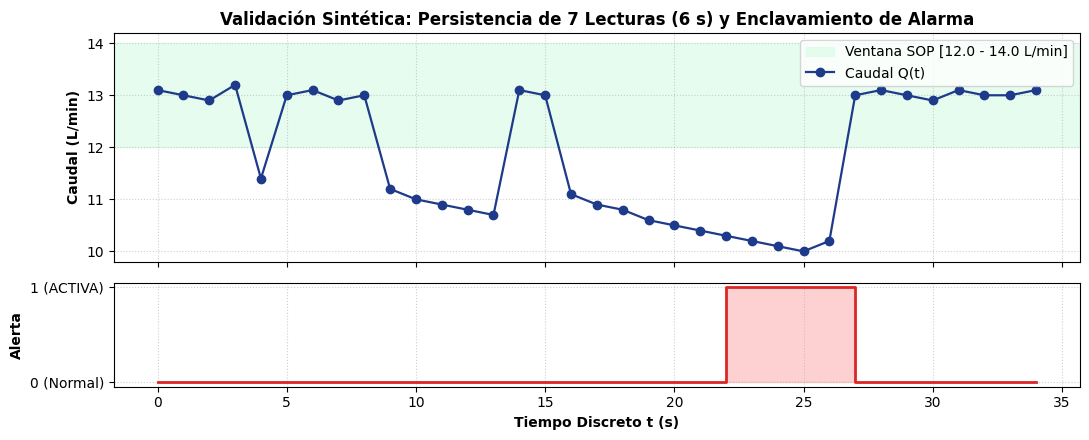

In [3]:
# @title 3. Ejecución y Visualización de la Validación Sintética
t_syn = np.arange(0, 35)
q_syn = np.array([
    13.1, 13.0, 12.9, 13.2, 11.4, 13.0, 13.1, 12.9, 13.0,  # t=4: ruido 1 lectura
    11.2, 11.0, 10.9, 10.8, 10.7, 13.1, 13.0,               # t=9..13: 5 lecturas (4 s < 6 s)
    11.1, 10.9, 10.8, 10.6, 10.5, 10.4, 10.3,               # t=16..22: 7 lecturas (6 s -> CONFIRMA en t=22)
    10.2, 10.1, 10.0, 10.2,                                 # t=23..26: persiste anomalía -> ALARMA ACTIVA
    13.0, 13.1, 13.0, 12.9, 13.1, 13.0, 13.0, 13.1          # t>=27: retorno a ventana -> ALARMA APAGADA
])
v_syn = np.ones_like(q_syn, dtype=bool)
r_syn = (q_syn >= 12.0) & (q_syn <= 14.0)
al_syn, ev_syn = eval_persistence_latch(r_syn, v_syn)

df_syn = pd.DataFrame({
    't_seg': t_syn,
    'Caudal_Lmin': q_syn,
    'En_Rango': r_syn,
    'Alerta_Activa': al_syn
})
print(f"Eventos confirmados en prueba sintética: {ev_syn}")
print(df_syn.iloc[15:29].to_string(index=False))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 4.5), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})
ax1.axhspan(12.0, 14.0, color='#DCFCE7', alpha=0.7, label='Ventana SOP [12.0 - 14.0 L/min]')
ax1.plot(t_syn, q_syn, marker='o', color='#1E3A8A', linewidth=1.6, label='Caudal Q(t)')
ax1.set_ylabel('Caudal (L/min)', fontweight='bold')
ax1.set_title('Validación Sintética: Persistencia de 7 Lecturas (6 s) y Enclavamiento de Alarma', fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right')

ax2.step(t_syn, al_syn, where='post', color='#DC2626', linewidth=2.0, label='Señal Alerta Enclavada')
ax2.fill_between(t_syn, 0, al_syn, step='post', color='#FCA5A5', alpha=0.5)
ax2.set_ylabel('Alerta', fontweight='bold')
ax2.set_xlabel('Tiempo Discreto t (s)', fontweight='bold')
ax2.set_yticks([0, 1])
ax2.set_yticklabels(['0 (Normal)', '1 (ACTIVA)'])
ax2.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


## VEN4 · Simulación de E0–E4 con semilla fija

In [4]:
# @title 4. Ejecución de los Experimentos Numéricos (18,000 Observaciones)
np.random.seed(SEED)

scenarios_cfg = {
    'E0 (AS-IS Base)': {
        'mu': {'V': 18.8, 'I': 142.0, 'Q': 11.3},
        'sigma': {'V': 1.15, 'I': 18.5, 'Q': 1.25},
        'phi': 0.78, 'n_events': (3, 5), 'event_dur': (8, 16),
        'p_nan': 0.010, 'fpy_base': 0.855, 'cycle_base': 55.0
    },
    'E1 (SOP Estandarizado)': {
        'mu': {'V': 20.5, 'I': 140.0, 'Q': 13.0},
        'sigma': {'V': 0.75, 'I': 12.0, 'Q': 0.85},
        'phi': 0.72, 'n_events': (2, 4), 'event_dur': (7, 13),
        'p_nan': 0.008, 'fpy_base': 0.900, 'cycle_base': 49.5
    },
    'E2 (SOP + TPM)': {
        'mu': {'V': 20.5, 'I': 140.0, 'Q': 13.0},
        'sigma': {'V': 0.55, 'I': 9.0, 'Q': 0.45},
        'phi': 0.68, 'n_events': (1, 3), 'event_dur': (6, 10),
        'p_nan': 0.004, 'fpy_base': 0.935, 'cycle_base': 45.0
    },
    'E3 (SOP + TPM + 5S + Alerta)': {
        'mu': {'V': 20.5, 'I': 140.0, 'Q': 13.0},
        'sigma': {'V': 0.35, 'I': 5.8, 'Q': 0.28},
        'phi': 0.60, 'n_events': (1, 2), 'event_dur': (4, 8),
        'p_nan': 0.0025, 'fpy_base': 0.965, 'cycle_base': 41.2
    },
    'E4 (Estrés Alta Demanda)': {
        'mu': {'V': 20.4, 'I': 141.0, 'Q': 12.9},
        'sigma': {'V': 0.45, 'I': 7.5, 'Q': 0.38},
        'phi': 0.65, 'n_events': (2, 3), 'event_dur': (5, 9),
        'p_nan': 0.0035, 'fpy_base': 0.950, 'cycle_base': 42.8
    }
}

all_orders = []

for sc_name, cfg in scenarios_cfg.items():
    for order_id in range(1, N_ORDERS + 1):
        valid, in_rng, alarms, events_cnt = {}, {}, {}, {}
        for var in ['V', 'I', 'Q']:
            x = np.zeros(T_ORDER)
            x[0] = cfg['mu'][var]
            eps = np.random.normal(0, cfg['sigma'][var] * np.sqrt(1 - cfg['phi']**2), T_ORDER)
            for t in range(1, T_ORDER):
                x[t] = cfg['mu'][var] + cfg['phi'] * (x[t-1] - cfg['mu'][var]) + eps[t]

            k_ev = np.random.randint(cfg['n_events'][0], cfg['n_events'][1] + 1)
            for _ in range(k_ev):
                if np.random.rand() < 0.45:
                    dur = np.random.randint(cfg['event_dur'][0], cfg['event_dur'][1] + 1)
                    start = np.random.randint(10, T_ORDER - dur - 5)
                    direction = -1 if var in ['V', 'Q'] else np.random.choice([-1, 1])
                    shift = (WINDOWS[var][1] - WINDOWS[var][0]) * 0.85 * direction
                    x[start:start+dur] += shift

            v_mask = np.ones(T_ORDER, dtype=bool)
            for t in range(T_ORDER - 1):
                if np.random.rand() < cfg['p_nan']:
                    v_mask[t:t+2] = False

            lo, hi = WINDOWS[var]
            r_mask = (x >= lo) & (x <= hi)
            al, ev_c = eval_persistence_latch(r_mask, v_mask)

            valid[var], in_rng[var], alarms[var], events_cnt[var] = v_mask, r_mask, al, ev_c

        c_V = np.mean(in_rng['V'][valid['V']]) * 100
        c_I = np.mean(in_rng['I'][valid['I']]) * 100
        c_Q = np.mean(in_rng['Q'][valid['Q']]) * 100
        all_valid = valid['V'] & valid['I'] & valid['Q']
        completitud = np.mean(all_valid) * 100
        joint_ok = in_rng['V'][all_valid] & in_rng['I'][all_valid] & in_rng['Q'][all_valid]
        c_conjunta = np.mean(joint_ok) * 100
        tot_alarms_sec = int(np.sum((alarms['V'] | alarms['I'] | alarms['Q']) == 1))
        tot_events = events_cnt['V'] + events_cnt['I'] + events_cnt['Q']
        prob_pass = np.clip(cfg['fpy_base'] + 0.0012 * (c_conjunta - 75.0) - 0.002 * tot_alarms_sec, 0.50, 0.995)
        fpy_order = 100.0 if np.random.rand() < prob_pass else 0.0
        cycle_time = np.random.normal(cfg['cycle_base'], 2.4) + (4.5 if fpy_order == 0 else 0.0)

        all_orders.append({
            'Escenario': sc_name, 'Orden': order_id,
            'Cumpl_V_%': c_V, 'Cumpl_I_%': c_I, 'Cumpl_Q_%': c_Q,
            'Conformidad_Conjunta_%': c_conjunta, 'Completitud_%': completitud,
            'Eventos_Confirmados': tot_events, 'Segundos_Alarma_Activa': tot_alarms_sec,
            'FPY_%': fpy_order, 'Tiempo_Ciclo_min': cycle_time
        })

df_resultados = pd.DataFrame(all_orders)
df_resultados.to_csv("resultados_simulacion_AZIMUTH.csv", index=False)

tabla_resumen = df_resultados.groupby('Escenario', sort=False).agg(
    Ordenes=('Orden', 'count'),
    Obs_Totales=('Orden', lambda s: len(s)*T_ORDER),
    Voltaje_Mean=('Cumpl_V_%', 'mean'),
    Corriente_Mean=('Cumpl_I_%', 'mean'),
    Caudal_Mean=('Cumpl_Q_%', 'mean'),
    Conjunta_Mean=('Conformidad_Conjunta_%', 'mean'),
    Conjunta_SD=('Conformidad_Conjunta_%', 'std'),
    Completitud_Mean=('Completitud_%', 'mean'),
    Eventos_Prom=('Eventos_Confirmados', 'mean'),
    Alarma_Seg_Prom=('Segundos_Alarma_Activa', 'mean'),
    FPY_Mean=('FPY_%', 'mean'),
    Ciclo_Mean=('Tiempo_Ciclo_min', 'mean'),
    Ciclo_SD=('Tiempo_Ciclo_min', 'std')
).reset_index()

display(tabla_resumen.round(2))


,Escenario,Ordenes,Obs_Totales,Voltaje_Mean,Corriente_Mean,Caudal_Mean,Conjunta_Mean,Conjunta_SD,Completitud_Mean,Eventos_Prom,Alarma_Seg_Prom,FPY_Mean,Ciclo_Mean,Ciclo_SD
0,E0 (AS-IS Base),20,3600,24.56,66.31,24.84,3.80,2.10,94.28,13.80,115.55,50.0,57.47,3.34
1,E1 (SOP Estandarizado),20,3600,76.05,84.86,71.37,46.39,7.51,95.83,3.55,10.95,80.0,50.97,2.87
2,E2 (SOP + TPM),20,3600,88.73,94.10,94.50,78.48,5.59,97.39,1.65,4.05,100.0,45.06,2.06
3,E3 (SOP + TPM + 5S + Alerta),20,3600,98.05,97.62,96.62,92.42,3.59,98.61,0.70,1.00,100.0,40.84,2.32
4,E4 (Estrés Alta Demanda),20,3600,93.08,95.87,94.89,84.72,3.71,97.75,1.30,2.95,95.0,43.43,3.03


## VEN5 · Contrastes Welch, Mann–Whitney, Fisher, Holm

In [5]:
# ==============================================================================
# CELDA 5 DE 6 (ACTUALIZADA): CONTRASTES INFERENCIALES COMPLETOS (E0 vs. E1-E4)
# Incluye: Media ± DE, Delta%, t de Welch, U de Mann-Whitney, Fisher Exacta (FPY),
#          Tamaños de Efecto (d de Cohen, r rank-biserial) y Holm-Bonferroni
# ==============================================================================
import numpy as np
import pandas as pd
from scipy import stats

# 1. Definición de variables, dirección de mejora y jerarquía de hipótesis
variables_eval = [
    ('Cumpl_V_%', 'Cumplimiento de Voltaje (%)', 'greater', 'H1a - Estabilidad Arco'),
    ('Cumpl_I_%', 'Cumplimiento de Corriente (%)', 'greater', 'H1b - Estabilidad Térmica'),
    ('Cumpl_Q_%', 'Cumplimiento de Caudal Gas (%)', 'greater', 'H1c - Protección Gaseosa'),
    ('Conformidad_Conjunta_%', 'Conformidad Conjunta 3V (%)', 'greater', 'H1 - Calidad Conjunta'),
    ('Completitud_%', 'Completitud de Datos (%)', 'greater', 'H_Tel - Integridad 1 Hz'),
    ('Segundos_Alarma_Activa', 'Tiempo Alarma Enclavada (s/OT)', 'less', 'H_Ctrl - Persistencia 6 s / 7 lecturas'),
    ('Eventos_Confirmados', 'Eventos Confirmados (ev/OT)', 'less', 'H_Ctrl - Desviaciones'),
    ('Tiempo_Ciclo_min', 'Tiempo de Ciclo Crítico (min)', 'less', 'H2 - Productividad'),
    ('FPY_%', 'First Pass Yield — FPY (%)', 'greater', 'H3 - Rendimiento FPY')
]

# Extraer subconjunto de línea base E0 (n = 20 OT)
e0_df = df_resultados[df_resultados['Escenario'].str.startswith('E0')]
escenarios_comp = ['E1', 'E2', 'E3', 'E4']

registros_tabla11b = []

for col, etiqueta, alt, hip_id in variables_eval:
    x0 = e0_df[col].values
    m0, s0 = np.mean(x0), np.std(x0, ddof=1)
    bloque_var = []

    for sc in escenarios_comp:
        x1 = df_resultados[df_resultados['Escenario'].str.startswith(sc)][col].values
        m1, s1 = np.mean(x1), np.std(x1, ddof=1)
        delta_pct = ((m1 - m0) / m0) * 100.0

        # Prueba no paramétrica U de Mann-Whitney (direccional) y r rank-biserial
        u_stat, p_u = stats.mannwhitneyu(x1, x0, alternative=alt)
        r_rb = abs(1.0 - (2.0 * u_stat) / (len(x0) * len(x1)))

        if col == 'FPY_%':
            # Variable binaria (0% / 100%): Prueba Exacta de Fisher (tabla 2x2)
            pass0, fail0 = int(np.sum(x0 == 100.0)), int(np.sum(x0 == 0.0))
            pass1, fail1 = int(np.sum(x1 == 100.0)), int(np.sum(x1 == 0.0))
            tabla_2x2 = [[pass1, fail1], [pass0, fail0]]
            _, p_fisher_1c = stats.fisher_exact(tabla_2x2, alternative='greater')
            _, p_fisher_2c = stats.fisher_exact(tabla_2x2, alternative='two-sided')

            bloque_var.append({
                'Hipotesis': hip_id,
                'Variable': etiqueta,
                'Contraste': f'E0 vs. {sc}',
                'Rol': 'Primario Confirmatorio' if sc == 'E3' else 'Secundario',
                'E0_Media_DE': f'{m0:.2f} ± {s0:.2f} ({pass0}/20)',
                'Ei_Media_DE': f'{m1:.2f} ± {s1:.2f} ({pass1}/20)',
                'Delta_%': round(delta_pct, 2),
                't_Welch': np.nan,
                'p_t_o_Fisher_1cola': p_fisher_1c,
                'p_t_bilateral': np.nan,
                'p_Fisher_2colas': p_fisher_2c,
                'U_MannWhitney': round(u_stat, 1),
                'p_U': p_u,
                'd_Cohen': np.nan,
                'r_rank_biserial': round(r_rb, 3),
                'p_raw': p_fisher_1c
            })
        else:
            # Variables continuas: Prueba t de Welch y tamaño de efecto d de Cohen
            t_stat, p_t = stats.ttest_ind(x1, x0, equal_var=False, alternative=alt)
            _, p_t_bilat = stats.ttest_ind(x1, x0, equal_var=False, alternative='two-sided')
            sd_pooled = np.sqrt((s0**2 + s1**2) / 2.0)
            d_cohen = abs(m1 - m0) / sd_pooled

            bloque_var.append({
                'Hipotesis': hip_id,
                'Variable': etiqueta,
                'Contraste': f'E0 vs. {sc}',
                'Rol': 'Primario Confirmatorio' if sc == 'E3' else 'Secundario',
                'E0_Media_DE': f'{m0:.2f} ± {s0:.2f}',
                'Ei_Media_DE': f'{m1:.2f} ± {s1:.2f}',
                'Delta_%': round(delta_pct, 2),
                't_Welch': round(t_stat, 2),
                'p_t_o_Fisher_1cola': p_t,
                'p_t_bilateral': p_t_bilat,
                'p_Fisher_2colas': np.nan,
                'U_MannWhitney': round(u_stat, 1),
                'p_U': p_u,
                'd_Cohen': round(d_cohen, 2),
                'r_rank_biserial': round(r_rb, 3),
                'p_raw': p_t
            })

    # 2. Ajuste secuencial de Holm-Bonferroni (m = 4 contrastes, FWER <= 0.05)
    orden_p = np.argsort([item['p_raw'] for item in bloque_var])
    m_contrastes = len(bloque_var)
    for rango, idx in enumerate(orden_p):
        alpha_hb = 0.05 / (m_contrastes - rango)
        bloque_var[idx]['Alpha_HB'] = round(alpha_hb, 4)
        bloque_var[idx]['Decision_HB'] = (
            'Rechaza H0' if bloque_var[idx]['p_raw'] < alpha_hb else 'No rechaza H0'
        )

    registros_tabla11b.extend(bloque_var)

# 3. Construcción y exportación de Tabla 11B (Tabla 28 en Anexo III)
df_tabla11b = pd.DataFrame(registros_tabla11b).drop(columns=['p_raw'])
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 1000)

print("=== TABLA 11B: CONTRASTES INFERENCIALES COMPLETOS (E0 vs. E1-E4) ===")
display(df_tabla11b)

# Exportación opcional a CSV/Excel desde Google Colab
df_tabla11b.to_csv('Tabla_11B_Resultados_VEN_SEED2026.csv', index=False, encoding='utf-8-sig')


=== TABLA 11B: CONTRASTES INFERENCIALES COMPLETOS (E0 vs. E1-E4) ===


,Hipotesis,Variable,Contraste,Rol,E0_Media_DE,Ei_Media_DE,Delta_%,t_Welch,p_t_o_Fisher_1cola,p_t_bilateral,p_Fisher_2colas,U_MannWhitney,p_U,d_Cohen,r_rank_biserial,Alpha_HB,Decision_HB
0,H1a - Estabilidad Arco,Cumplimiento de Voltaje (%),E0 vs. E1,Secundario,24.56 ± 7.44,76.05 ± 6.26,209.66,23.69,3.213959e-24,6.427918e-24,NaN,400.0,3.397808e-08,7.49,1.000,0.0250,Rechaza H0
1,H1a - Estabilidad Arco,Cumplimiento de Voltaje (%),E0 vs. E2,Secundario,24.56 ± 7.44,88.73 ± 5.07,261.31,31.86,5.987480e-27,1.197496e-26,NaN,400.0,3.397808e-08,10.08,1.000,0.0125,Rechaza H0
2,H1a - Estabilidad Arco,Cumplimiento de Voltaje (%),E0 vs. E3,Primario Confirmatorio,24.56 ± 7.44,98.05 ± 1.55,299.24,43.23,4.878746e-22,9.757492e-22,NaN,400.0,3.270566e-08,13.67,1.000,0.0500,Rechaza H0
3,H1a - Estabilidad Arco,Cumplimiento de Voltaje (%),E0 vs. E4,Secundario,24.56 ± 7.44,93.08 ± 3.25,278.99,37.73,1.543709e-24,3.087419e-24,NaN,400.0,3.378690e-08,11.93,1.000,0.0167,Rechaza H0
4,H1b - Estabilidad Térmica,Cumplimiento de Corriente (%),E0 vs. E1,Secundario,66.31 ± 6.05,84.86 ± 4.18,27.98,11.28,2.636906e-13,5.273812e-13,NaN,398.0,4.567395e-08,3.57,0.990,0.0500,Rechaza H0
5,H1b - Estabilidad Térmica,Cumplimiento de Corriente (%),E0 vs. E2,Secundario,66.31 ± 6.05,94.10 ± 3.40,41.91,17.92,7.682999e-18,1.536600e-17,NaN,400.0,3.393019e-08,5.67,1.000,0.0167,Rechaza H0
6,H1b - Estabilidad Térmica,Cumplimiento de Corriente (%),E0 vs. E3,Primario Confirmatorio,66.31 ± 6.05,97.62 ± 2.03,47.22,21.95,2.472921e-17,4.945842e-17,NaN,400.0,3.188057e-08,6.94,1.000,0.0250,Rechaza H0
7,H1b - Estabilidad Térmica,Cumplimiento de Corriente (%),E0 vs. E4,Secundario,66.31 ± 6.05,95.87 ± 3.10,44.59,19.46,3.092477e-18,6.184953e-18,NaN,400.0,3.383460e-08,6.15,1.000,0.0125,Rechaza H0
8,H1c - Protección Gaseosa,Cumplimiento de Caudal Gas (%),E0 vs. E1,Secundario,24.84 ± 8.24,71.37 ± 5.24,187.33,21.31,7.415003e-21,1.483001e-20,NaN,400.0,3.393019e-08,6.74,1.000,0.0500,Rechaza H0
9,H1c - Protección Gaseosa,Cumplimiento de Caudal Gas (%),E0 vs. E2,Secundario,24.84 ± 8.24,94.50 ± 3.73,280.44,34.43,7.935925e-24,1.587185e-23,NaN,400.0,3.383460e-08,10.89,1.000,0.0125,Rechaza H0


## VEN6 · Gráficos: metas oficiales de diseño

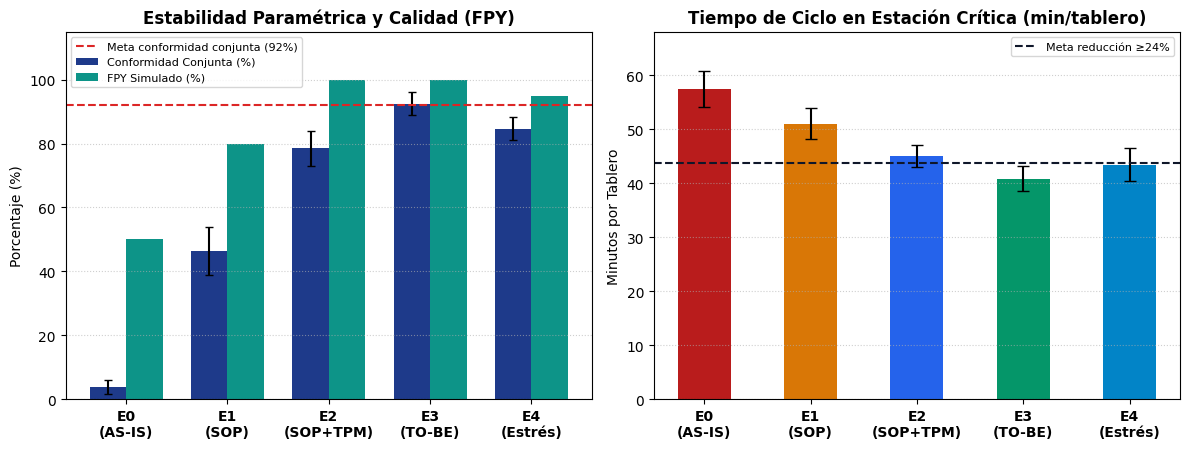

In [6]:
# @title 6. Visualización Comparativa de Resultados Experimentales (E0 - E4)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
short_names = ['E0\n(AS-IS)', 'E1\n(SOP)', 'E2\n(SOP+TPM)', 'E3\n(TO-BE)', 'E4\n(Estrés)']
x_pos = np.arange(len(short_names))
width = 0.36

b1 = axes[0].bar(x_pos - width/2, tabla_resumen['Conjunta_Mean'], width, yerr=tabla_resumen['Conjunta_SD'],
                 capsize=3, label='Conformidad Conjunta (%)', color='#1E3A8A')
b2 = axes[0].bar(x_pos + width/2, tabla_resumen['FPY_Mean'], width,
                 label='FPY Simulado (%)', color='#0D9488')
axes[0].axhline(92.0, color='#DC2626', linestyle='--', label='Meta conformidad conjunta (92%)')
axes[0].set_title('Estabilidad Paramétrica y Calidad (FPY)', fontweight='bold')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(short_names, fontweight='bold')
axes[0].set_ylabel('Porcentaje (%)')
axes[0].set_ylim(0, 115)
axes[0].grid(axis='y', linestyle=':', alpha=0.6)
axes[0].legend(loc='upper left', fontsize=8)

b3 = axes[1].bar(x_pos, tabla_resumen['Ciclo_Mean'], width=0.5, yerr=tabla_resumen['Ciclo_SD'],
                 capsize=4, color=['#B91C1C', '#D97706', '#2563EB', '#059669', '#0284C7'])
axes[1].axhline(tabla_resumen.loc[0, 'Ciclo_Mean'] * 0.76, color='#0F172A', linestyle='--', label='Meta reducción ≥24%')
axes[1].set_title('Tiempo de Ciclo en Estación Crítica (min/tablero)', fontweight='bold')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(short_names, fontweight='bold')
axes[1].set_ylabel('Minutos por Tablero')
axes[1].set_ylim(0, 68)
axes[1].grid(axis='y', linestyle=':', alpha=0.6)
axes[1].legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()


## VEN7 · Control de calidad metodológico y dictamen de metas
La aceptación de diseño se evalúa con **conformidad conjunta ≥ 92 %** y **reducción del ciclo ≥ 24 % respecto a E0** (metas únicas de Tabla 6). Estadística favorable no equivale a cumplimiento de la meta. Completitud exige **≥97 %**; FPY se conserva como proxy exploratorio, fuera del criterio de aprobación. El p bilateral para completitud E1 es ≈0,052, no concluyente. Las cifras reales de planta no se generan en este cuaderno.

In [7]:
import platform
assert N_ORDERS==20 and T_ORDER==180 and len(df_resultados)==100
assert len(tabla_resumen)==5 and len(df_tabla11b)==36
assert list(df_resultados['Escenario'].value_counts().values)==[20]*5
assert int(df_syn.loc[df_syn['Alerta_Activa'].eq(1),'t_seg'].min()) == 22
assert bool((df_syn[(df_syn.t_seg>=22)&(df_syn.t_seg<=26)]['Alerta_Activa']==1).all())
assert int(df_syn.loc[df_syn.t_seg==27,'Alerta_Activa'].iloc[0])==0

# Verifica que una muestra ausente rompe continuidad y no es recuperación normal.
assert eval_persistence_latch(np.zeros(6,dtype=bool), np.ones(6,dtype=bool))[1]==0
assert eval_persistence_latch(np.zeros(7,dtype=bool), np.ones(7,dtype=bool))[1]==1
prueba_gap_valid = np.ones(14,dtype=bool); prueba_gap_valid[6]=False
assert eval_persistence_latch(np.zeros(14,dtype=bool), prueba_gap_valid)[1] == 1  # el nuevo episodio t=7..13 cumple 7
assert np.all(eval_persistence_latch(np.zeros(13,dtype=bool), np.array([1]*6+[0]+[1]*6,dtype=bool))[0]==0)

base = tabla_resumen.iloc[0]
meta = []
for _,r in tabla_resumen.iterrows():
    red = (base['Ciclo_Mean']-r['Ciclo_Mean'])/base['Ciclo_Mean']*100
    meta.append({'Escenario':r['Escenario'], 'Conformidad (%)':round(r['Conjunta_Mean'],2),
                 'Meta_92': 'CUMPLE' if r['Conjunta_Mean']>=92 else 'NO CUMPLE',
                 'Reducción ciclo (%)':round(red,2),
                 'Meta_24': 'CUMPLE' if red>=24 else 'NO CUMPLE',
                 'Completitud (%)':round(r['Completitud_Mean'],2),
                 'Meta_97': 'CUMPLE' if r['Completitud_Mean']>=97 else 'NO CUMPLE'})
resumen_aceptacion=pd.DataFrame(meta)
display(resumen_aceptacion)
sub=df_tabla11b[(df_tabla11b['Variable']=='Completitud de Datos (%)') & (df_tabla11b['Contraste']=='E0 vs. E1')]
assert len(sub)==1
p1=float(sub['p_t_o_Fisher_1cola'].iloc[0]);p2=float(sub['p_t_bilateral'].iloc[0])
assert 0.025<p1<0.027 and 0.051<p2<0.053
assert float(tabla_resumen.iloc[1]['Completitud_Mean'])<97.0
print(f'Complejidad H_TELEMETRIA E0 vs E1: p unilateral={p1:.5f}; p bilateral={p2:.5f}; NO cumple meta 97%.')
print('VEN | Control QA 7 lecturas, alarma ON/OFF y gaps: OK; 36 comparaciones reproducidas.')
print('VEN | Versiones locales:', platform.python_version(), 'NumPy', np.__version__, 'SciPy', __import__('scipy').__version__)
# Entregables exportados por las celdas anteriores incluyen CSV de datos OT y Tabla 11-b.

,Escenario,Conformidad (%),Meta_92,Reducción ciclo (%),Meta_24,Completitud (%),Meta_97
0,E0 (AS-IS Base),3.80,NO CUMPLE,0.00,NO CUMPLE,94.28,NO CUMPLE
1,E1 (SOP Estandarizado),46.39,NO CUMPLE,11.31,NO CUMPLE,95.83,NO CUMPLE
2,E2 (SOP + TPM),78.48,NO CUMPLE,21.60,NO CUMPLE,97.39,CUMPLE
3,E3 (SOP + TPM + 5S + Alerta),92.42,CUMPLE,28.94,CUMPLE,98.61,CUMPLE
4,E4 (Estrés Alta Demanda),84.72,NO CUMPLE,24.43,CUMPLE,97.75,CUMPLE


Complejidad H_TELEMETRIA E0 vs E1: p unilateral=0.02602; p bilateral=0.05204; NO cumple meta 97%.
VEN | Control QA 7 lecturas, alarma ON/OFF y gaps: OK; 36 comparaciones reproducidas.
VEN | Versiones locales: 3.13.18 NumPy 2.4.6 SciPy 1.16.3


### Interpretación defendible
El escenario E3 es el único que alcanza simultáneamente las metas primarias de conformidad y ciclo, **dentro de este DOE sintético**. Para completitud E1, no debe confundirse el rechazo unilateral de H0 sobre cambio promedio con alcanzar ≥97 % ni con significancia bilateral. Los intervalos operativos usados para la producción necesitan verificación con WPS/SOP reales. El código nunca demuestra por sí mismo calidad metalúrgica, hermeticidad IP65/IP66, impacto financiero o reducción real de no conformidades.